# Faster R-CNN detector — PASCAL VOC 2007

This notebook trains/evaluates TorchVision's **Faster R-CNN** detector with a ResNet-50-FPN backbone on PASCAL VOC 2007.

In [1]:
# Cell 1: Install dependencies
!pip -q install torch torchvision matplotlib pandas tqdm scikit-learn opencv-contrib-python-headless

In [2]:
# Cell 2: Imports and configuration
import os, time, random, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision.datasets import VOCDetection
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VOC_ROOT = "/content/VOCdevkit"
QUICK_RUN = True   # Set False for a longer run
TRAIN_LIMIT = 300 if QUICK_RUN else None
TEST_LIMIT = 100 if QUICK_RUN else None
BATCH_SIZE = 8
NUM_WORKERS = 2
print("Device:", DEVICE)

Device: cuda


In [3]:
# Cell 3: Download dataset
# torchvision downloads/extracts the official VOC 2007 archives.
train_raw = VOCDetection(root=VOC_ROOT, year="2007", image_set="trainval", download=True)
test_raw  = VOCDetection(root=VOC_ROOT, year="2007", image_set="test", download=True)
print("Downloaded. Trainval:", len(train_raw), "| Test:", len(test_raw))

100%|██████████| 460M/460M [00:18<00:00, 25.5MB/s]
100%|██████████| 451M/451M [00:32<00:00, 14.0MB/s]


Downloaded. Trainval: 5011 | Test: 4952


In [4]:
# Cell 4: VOC class mapping and annotation parser
CLASSES = ["aeroplane","bicycle","bird","boat","bottle","bus","car","cat","chair","cow",
           "diningtable","dog","horse","motorbike","person","pottedplant","sheep","sofa",
           "train","tvmonitor"]
CLASS_TO_ID = {name:i+1 for i,name in enumerate(CLASSES)}  # 0 is background

def parse_voc_target(ann, width, height):
    objs = ann["annotation"].get("object", [])
    if isinstance(objs, dict): objs = [objs]
    boxes, labels = [], []
    for obj in objs:
        name = obj.get("name")
        if name not in CLASS_TO_ID:
            continue
        bb = obj["bndbox"]
        x1 = max(0, float(bb["xmin"])-1); y1 = max(0, float(bb["ymin"])-1)
        x2 = min(float(width), float(bb["xmax"])); y2 = min(float(height), float(bb["ymax"]))
        if x2 > x1 and y2 > y1:
            boxes.append([x1,y1,x2,y2]); labels.append(CLASS_TO_ID[name])
    if not boxes:
        return torch.zeros((0,4),dtype=torch.float32), torch.zeros((0,),dtype=torch.int64)
    return torch.tensor(boxes,dtype=torch.float32), torch.tensor(labels,dtype=torch.int64)

In [5]:
# Cell 5: Dataset and data loaders
class VOCDataset(Dataset):
    def __init__(self, raw, limit=None):
        self.raw = raw
        self.indices = list(range(len(raw)))
        if limit is not None: self.indices = self.indices[:limit]
    def __len__(self): return len(self.indices)
    def __getitem__(self, idx):
        img, ann = self.raw[self.indices[idx]]
        w,h = img.size
        boxes, labels = parse_voc_target(ann,w,h)
        img = TF.to_tensor(img)
        target = {"boxes":boxes, "labels":labels, "image_id":torch.tensor([self.indices[idx]])}
        return img,target

def detection_collate(batch):
    return tuple(zip(*batch))

train_ds = VOCDataset(train_raw, TRAIN_LIMIT)
test_ds = VOCDataset(test_raw, TEST_LIMIT)
train_loader = DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,collate_fn=detection_collate)
test_loader = DataLoader(test_ds,batch_size=1,shuffle=False,num_workers=NUM_WORKERS,collate_fn=detection_collate)
print("Usable train images:",len(train_ds),"| test images:",len(test_ds))

Usable train images: 300 | test images: 100


## Cell 6 — Create Faster R-CNN model

In [6]:
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
NUM_CLASSES = 21  # 20 VOC object classes + background
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features,NUM_CLASSES)
model.to(DEVICE)
optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],lr=0.002,momentum=0.9,weight_decay=0.0005)
print("Model ready.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 179MB/s]


Model ready.


## Cell 7 — Train detector

In [7]:
EPOCHS = 1 if QUICK_RUN else 5
loss_history=[]
for epoch in range(EPOCHS):
    model.train(); total=0.0
    for images,targets in tqdm(train_loader,desc=f"Epoch {epoch+1}/{EPOCHS}"):
        images=[x.to(DEVICE) for x in images]
        targets=[{k:v.to(DEVICE) for k,v in t.items()} for t in targets]
        loss_dict=model(images,targets)
        loss=sum(loss_dict.values())
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += float(loss.detach().cpu())
    avg=total/max(1,len(train_loader)); loss_history.append(avg)
    print(f"Epoch {epoch+1}: loss={avg:.4f}")
os.makedirs("/content/results",exist_ok=True)
torch.save(model.state_dict(),"/content/results/faster_rcnn_voc2007.pth")

Epoch 1/1:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 1: loss=1.0582


## Cell 8 — Evaluate mAP and inference speed

In [8]:
# Uses TorchMetrics COCO mAP if available; installs it if necessary.
!pip -q install torchmetrics pycocotools
from torchmetrics.detection.mean_ap import MeanAveragePrecision
metric = MeanAveragePrecision(box_format="xyxy",iou_type="bbox")
model.eval(); elapsed=[]; n_images=0
with torch.no_grad():
    for images,targets in tqdm(test_loader,desc="Evaluating"):
        imgs=[x.to(DEVICE) for x in images]
        if DEVICE.type=="cuda": torch.cuda.synchronize()
        start=time.perf_counter(); outputs=model(imgs)
        if DEVICE.type=="cuda": torch.cuda.synchronize()
        elapsed.append(time.perf_counter()-start); n_images += len(imgs)
        preds=[]
        for out in outputs:
            preds.append({k:out[k].detach().cpu() for k in ["boxes","scores","labels"]})
        gts=[{"boxes":t["boxes"].cpu(),"labels":t["labels"].cpu()} for t in targets]
        metric.update(preds,gts)
result=metric.compute()
map50=float(result["map_50"]); map_all=float(result["map"])
det_metrics={"model":"Faster R-CNN","mAP50":map50,"mAP50_95":map_all,
             "mean_latency_ms":1000*np.mean(elapsed),"images_per_second":n_images/max(sum(elapsed),1e-9)}
print(pd.Series(det_metrics))
pd.DataFrame([det_metrics]).to_csv("/content/results/faster_rcnn_metrics.csv",index=False)

Evaluating:   0%|          | 0/100 [00:00<?, ?it/s]

model                Faster R-CNN
mAP50                    0.074099
mAP50_95                 0.032848
mean_latency_ms        159.468262
images_per_second         6.27084
dtype: object


## Cell 9 — Plot loss and detection metrics

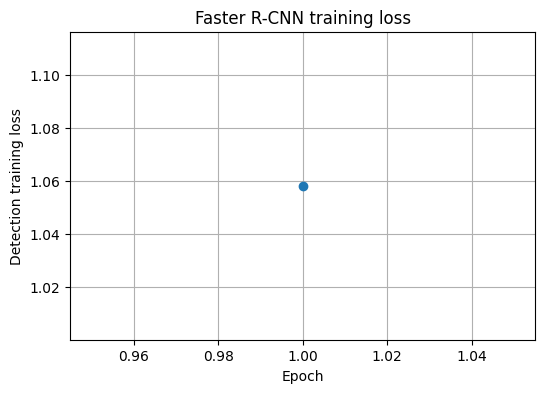

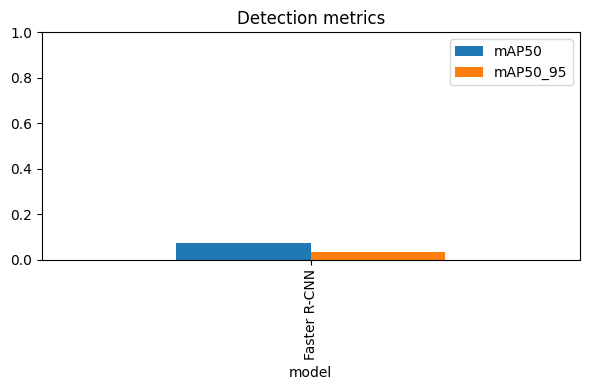

In [9]:
plt.figure(figsize=(6,4)); plt.plot(range(1,len(loss_history)+1),loss_history,marker="o")
plt.xlabel("Epoch"); plt.ylabel("Detection training loss"); plt.title("Faster R-CNN training loss"); plt.grid(True); plt.show()
pd.DataFrame([det_metrics]).set_index("model")[["mAP50","mAP50_95"]].plot(kind="bar",ylim=(0,1),figsize=(6,4),title="Detection metrics")
plt.tight_layout(); plt.show()

## Cell 10 — Visualize predictions

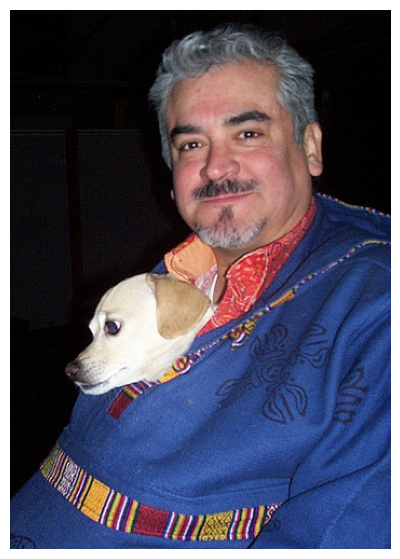

In [10]:
import matplotlib.patches as patches
model.eval()
img,target=test_ds[0]
with torch.no_grad(): out=model([img.to(DEVICE)])[0]
fig,ax=plt.subplots(1,figsize=(10,7)); ax.imshow(img.permute(1,2,0))
for box,lab,score in zip(out["boxes"].cpu(),out["labels"].cpu(),out["scores"].cpu()):
    if score < 0.5: continue
    x1,y1,x2,y2=box.tolist()
    ax.add_patch(patches.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,linewidth=2))
    ax.text(x1,y1,f"{CLASSES[int(lab)-1]} {float(score):.2f}",backgroundcolor="yellow")
ax.axis("off"); plt.show()

### Notes
- Pretrained COCO weights are used to initialize the detector; the VOC-specific predictor is trained on VOC labels.
- `QUICK_RUN=True` is only a smoke test and yields weak metrics. Use `False`, more epochs, and GPU for a serious comparison.
- This detector uses real bounding-box metrics (mAP); it is not directly comparable to the CNN classification F1 score.